### Pillow 1: Grundlagen - Übungen

Ein digitales Bild ist ein Raster aus **Pixeln** (Bildpunkten), jedes mit einer Farbe. Mit dem Paket **Pillow** (Modulname `PIL`) erzeugst, bearbeitest und
speicherst du Bilder in Python. In diesem Notebook lernst du, wie Pillow Bilder, Farben und Pixel darstellt, wie du einzelne Pixel liest und setzt,
mit Schleifen Muster erzeugst und Bilddateien speicherst und öffnest.

Die Reihe hat vier Notebooks:

1. **Grundlagen**: Bilder erzeugen, Pixel, Farben, Speichern und Öffnen (dieses Notebook)
2. Zeichnen: Formen, Text, Grafiken mit Schleifen und Funktionen
3. Bearbeiten: Ausschneiden, Drehen, Filter, Helligkeit, Collagen, animierte GIFs
4. Pixel: Bildverarbeitung selbst programmieren, mit Schleifen und mit numpy

Vorausgesetzt werden die Notebooks *Schleifen*, *Tupel* und *Funktionen*.

**Bilder anzeigen:** Steht ein Bild in der **letzten Zeile** einer Zelle, zeigt JupyterLab es an. Mehrere Bilder in einer Zelle zeigt man mit `display(bild)` an.
Die erwarteten Ausgaben zeigen die Bilder höchstens 320 Pixel groß; große Bilder (Fotos) sind dort verkleinert.

**Fotos:** Neben den Notebooks liegen zwei Fotos mit je 640 × 427 Pixeln: `pagode.png` (ein chinesischer Tempel) und `bluete.png` (eine Blüte).
Fotos: Daniel Buechele, [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/), aus dem Paket scikit-learn.
Eigene Fotos kannst du mit dem Pfeil-Symbol über der Dateiliste links hochladen und dann mit `Image.open('dateiname.jpg')` öffnen.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

#### Bildanzeige einrichten

**Führe diese Zelle zuerst aus** (nach jedem Neustart des Kernels wieder). Im Browser-Python von JupyterLite zeigt `display(bild)` sonst nur ein leeres Bild an;
die Zelle sorgt dafür, dass Pillow-Bilder dort richtig übertragen werden. Wie sie funktioniert, musst du nicht verstehen.

In [ ]:
import base64
import io
from IPython import get_ipython
from PIL import Image

def als_png(bild):
    puffer = io.BytesIO()
    bild.save(puffer, 'PNG')
    return base64.b64encode(puffer.getvalue()).decode('ascii')

def kein_jpeg(bild):
    return None

ipython = get_ipython()
if ipython is not None:
    ipython.display_formatter.formatters['image/png'].for_type(Image.Image, als_png)
    ipython.display_formatter.formatters['image/jpeg'].for_type(Image.Image, kein_jpeg)
print('Bereit: Bilder werden auch mit display() angezeigt.')

## 1. Ein Bild erzeugen

#### `Image.new()`

`Image.new('RGB', (breite, hoehe), farbe)` erzeugt ein neues Bild, in dem jedes Pixel die angegebene Farbe hat. `'RGB'` ist der **Modus**: Jede Farbe besteht aus den
drei Anteilen **R**ot, **G**rün und **B**lau, jeder von 0 bis 255. Steht das Bild in der letzten Zeile der Zelle, wird es angezeigt.

- `bild.size` ist das Tupel `(breite, hoehe)`, `bild.width` und `bild.height` sind die einzelnen Werte.
- `bild.mode` ist der Modus.

In [ ]:
from PIL import Image

bild = Image.new('RGB', (200, 100), (255, 128, 0))
print(bild.size, bild.width, bild.height, bild.mode)
bild

#### Farben angeben

Eine Farbe kann man auf drei Arten angeben:

| Schreibweise | Beispiel | Bedeutung |
|---|---|---|
| Tupel | `(255, 0, 0)` | Rot, Grün, Blau von 0 bis 255 |
| Name | `'red'`, `'gold'`, `'navy'` | englische Farbnamen (wie in HTML) |
| Hex-Code | `'#ff8800'` | je zwei Hexadezimalziffern für Rot, Grün, Blau |

`(0, 0, 0)` ist Schwarz, `(255, 255, 255)` Weiß, gleiche Anteile ergeben Grau. `ImageColor.getrgb(farbe)` rechnet Namen und Hex-Codes in ein Tupel um.
Mehrere Bilder in einer Zelle zeigt `display(bild)` an.

In [ ]:
from PIL import Image, ImageColor

print(ImageColor.getrgb('gold'), ImageColor.getrgb('#ff8800'))
display(Image.new('RGB', (150, 40), 'navy'))
display(Image.new('RGB', (150, 40), '#ff8800'))
Image.new('RGB', (150, 40), (128, 128, 128))

#### Aufgabe 1.1

Erzeuge ein grünes Bild (`(0, 200, 0)`) mit 300 × 150 Pixeln, gib seine Größe aus und zeige es an.

**Erwartete Ausgabe:**

```
(300, 150)
```

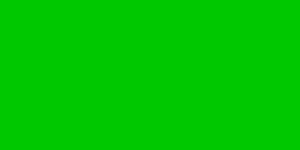

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (300, 150), (0, 200, 0))
print(bild.size)
bild
```

</details>

#### Aufgabe 1.2

Erzeuge ein quadratisches Bild mit 120 Pixeln Seitenlänge in der Farbe `'purple'` und zeige es an.

**Erwartete Ausgabe:**



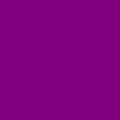

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
Image.new('RGB', (120, 120), 'purple')
```

</details>

#### Aufgabe 1.3

Gib die Farbanteile von `'orange'`, `'skyblue'` und `'#336699'` als Tupel aus.

**Erwartete Ausgabe:**

```
orange (255, 165, 0)
skyblue (135, 206, 235)
#336699 (51, 102, 153)
```

In [ ]:
from PIL import ImageColor
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import ImageColor
for farbe in ['orange', 'skyblue', '#336699']:
    print(farbe, ImageColor.getrgb(farbe))
```

</details>

#### Aufgabe 1.4

Zeige fünf Bilder mit 200 × 30 Pixeln untereinander an: Grau mit den Helligkeiten 0, 64, 128, 192 und 255 (alle drei Anteile gleich).

**Erwartete Ausgabe:**













In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
for wert in [0, 64, 128, 192, 255]:
    display(Image.new('RGB', (200, 30), (wert, wert, wert)))
```

</details>

#### Aufgabe 1.5

Mische Farben: Zeige die Farben `(255, 255, 0)`, `(0, 255, 255)` und `(255, 0, 255)` als Bilder mit 100 × 50 Pixeln an. Rot und Grün ergeben Gelb,
Grün und Blau ergeben Türkis (Cyan), Rot und Blau ergeben Magenta.

**Erwartete Ausgabe:**



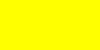

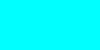

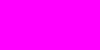

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
for farbe in [(255, 255, 0), (0, 255, 255), (255, 0, 255)]:
    display(Image.new('RGB', (100, 50), farbe))
```

</details>

#### Aufgabe 1.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image

bild = Image.new('RGB', (640, 480), 'white')
print(bild.size)
print(bild.width * bild.height)
print(bild.mode)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
(640, 480)
307200
RGB
```

- `size` ist `(breite, hoehe)`: `(640, 480)`.
- Das Bild hat `640 · 480 = 307200` Pixel.
- Der Modus ist `RGB`.

</details>

## 2. Pixel lesen und setzen

#### `getpixel()` und `putpixel()`

Jedes Pixel hat eine Position `(x, y)`. Der **Ursprung** `(0, 0)` ist oben links, `x` wächst nach rechts, `y` wächst **nach unten** (anders als im Mathematikunterricht).
Das Pixel unten rechts hat die Position `(breite - 1, hoehe - 1)`.

- `bild.getpixel((x, y))` gibt die Farbe des Pixels als Tupel zurück.
- `bild.putpixel((x, y), farbe)` setzt die Farbe eines Pixels.

Die Position ist ein Tupel, deshalb die doppelten Klammern.

In [ ]:
from PIL import Image

bild = Image.new('RGB', (20, 10), 'white')
bild.putpixel((0, 0), (255, 0, 0))
bild.putpixel((19, 9), (0, 0, 255))
print(bild.getpixel((0, 0)), bild.getpixel((19, 9)), bild.getpixel((5, 5)))
bild.resize((200, 100), Image.NEAREST)

#### Kleine Bilder vergrößert anzeigen

Ein Bild mit 20 × 10 Pixeln ist auf dem Bildschirm winzig. `bild.resize((200, 100), Image.NEAREST)` gibt eine vergrößerte Kopie zurück, in der jedes Pixel ein
10 × 10 großes Quadrat ist (`NEAREST`: jedes neue Pixel übernimmt die Farbe des nächsten alten, ohne zu glätten). Das Bild selbst bleibt unverändert.

Mit einer Schleife setzt man viele Pixel, z. B. eine waagerechte Linie in Zeile 4.

In [ ]:
from PIL import Image

bild = Image.new('RGB', (20, 10), 'white')
for x in range(20):
    bild.putpixel((x, 4), (0, 0, 0))
bild.resize((200, 100), Image.NEAREST)

#### Aufgabe 2.1

Erzeuge ein weißes Bild mit 10 × 10 Pixeln, setze die vier Eckpixel rot und gib ihre Farben zur Kontrolle aus. Zeige das Bild 20-fach vergrößert an (`NEAREST`).

**Erwartete Ausgabe:**

```
(255, 0, 0)
(255, 0, 0)
(255, 0, 0)
(255, 0, 0)
```

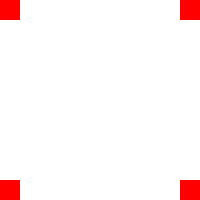

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (10, 10), 'white')
for ecke in [(0, 0), (9, 0), (0, 9), (9, 9)]:
    bild.putpixel(ecke, (255, 0, 0))
    print(bild.getpixel(ecke))
bild.resize((200, 200), Image.NEAREST)
```

</details>

#### Aufgabe 2.2

Zeichne in ein weißes 16 × 16-Bild eine senkrechte schwarze Linie in Spalte 5 und eine waagerechte blaue in Zeile 10. Zeige es 15-fach vergrößert an.

**Erwartete Ausgabe:**



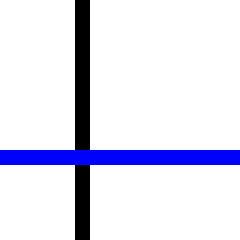

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (16, 16), 'white')
for y in range(16):
    bild.putpixel((5, y), (0, 0, 0))
for x in range(16):
    bild.putpixel((x, 10), (0, 0, 255))
bild.resize((240, 240), Image.NEAREST)
```

</details>

#### Aufgabe 2.3

Zeichne in ein weißes 12 × 12-Bild die beiden Diagonalen in Rot (von oben links nach unten rechts: `(i, i)`, die andere: `(11 - i, i)`). Zeige es 20-fach vergrößert an.

**Erwartete Ausgabe:**



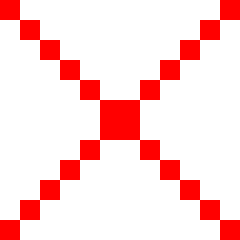

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (12, 12), 'white')
for i in range(12):
    bild.putpixel((i, i), (255, 0, 0))
    bild.putpixel((11 - i, i), (255, 0, 0))
bild.resize((240, 240), Image.NEAREST)
```

</details>

#### Aufgabe 2.4

Zeichne einen schwarzen Rahmen (1 Pixel breit) um ein gelbes Bild mit 30 × 20 Pixeln. Zähle dabei mit, wie viele Pixel du schwarz färbst (jedes nur einmal!),
und gib die Zahl aus. Zeige das Bild 8-fach vergrößert an.

**Erwartete Ausgabe:**

```
96
```

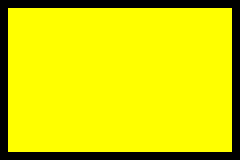

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (30, 20), 'yellow')
anzahl = 0
for x in range(30):
    for y in range(20):
        if x == 0 or x == 29 or y == 0 or y == 19:
            bild.putpixel((x, y), (0, 0, 0))
            anzahl += 1
print(anzahl)
bild.resize((240, 160), Image.NEAREST)
```

</details>

#### Aufgabe 2.5

Pixel-Kunst: Die Liste `muster` beschreibt ein Bild Zeile für Zeile, `#` ist schwarz, `.` ist weiß. Erzeuge daraus ein Bild (Breite = Länge einer Zeile, Höhe = Anzahl der Zeilen)
und zeige es 25-fach vergrößert an.

**Erwartete Ausgabe:**



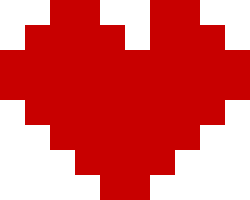

In [ ]:
from PIL import Image

muster = ['..##..##..',
          '.####.###.',
          '##########',
          '##########',
          '.########.',
          '..######..',
          '...####...',
          '....##....']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

muster = ['..##..##..',
          '.####.###.',
          '##########',
          '##########',
          '.########.',
          '..######..',
          '...####...',
          '....##....']
bild = Image.new('RGB', (len(muster[0]), len(muster)), 'white')
for y in range(len(muster)):
    for x in range(len(muster[y])):
        if muster[y][x] == '#':
            bild.putpixel((x, y), (200, 0, 0))
bild.resize((bild.width * 25, bild.height * 25), Image.NEAREST)
```

</details>

#### Aufgabe 2.6

Gib die Farben der Pixel `(0, 0)`, `(320, 200)` und `(639, 426)` des Fotos `pagode.png` aus (`Image.open('pagode.png')`).

**Erwartete Ausgabe:**

```
(0, 0) (174, 201, 231)
(320, 200) (237, 226, 222)
(639, 426) (15, 24, 7)
```

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
foto = Image.open('pagode.png')
for position in [(0, 0), (320, 200), (639, 426)]:
    print(position, foto.getpixel(position))
```

</details>

#### Aufgabe 2.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image

bild = Image.new('RGB', (5, 3), 'black')
bild.putpixel((4, 2), (255, 255, 255))
print(bild.getpixel((4, 2)))
print(bild.getpixel((2, 1)))
bild.putpixel((5, 3), (255, 0, 0))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
(255, 255, 255)
(0, 0, 0)
```

**Fehler:** `IndexError`

- Das Pixel unten rechts `(4, 2)` wurde weiß gesetzt: `(255, 255, 255)`.
- Alle anderen sind schwarz: `(0, 0, 0)`.
- Bei 5 × 3 Pixeln gehen `x` von 0 bis 4 und `y` von 0 bis 2. `(5, 3)` liegt außerhalb: `IndexError`.

</details>

## 3. Muster mit Schleifen

#### Für jedes Pixel eine Farbe berechnen

Mit zwei verschachtelten Schleifen über alle `x` und `y` kann man für jedes Pixel eine Farbe **ausrechnen**. Beim **Farbverlauf** hängt die Farbe von der Position ab:
Links (`x = 0`) ist der Rotanteil 0, rechts 255. Die Farbanteile müssen ganze Zahlen sein, deshalb `int()` bzw. `//`.

Bei großen Bildern ist `putpixel()` langsam. `pixel = bild.load()` liefert ein Objekt, mit dem `pixel[x, y] = farbe` schneller geht; hier reicht `putpixel()`.

In [ ]:
from PIL import Image

bild = Image.new('RGB', (256, 100))
for x in range(256):
    for y in range(100):
        bild.putpixel((x, y), (x, 0, 255 - x))
bild

#### Aufgabe 3.1

Erzeuge einen waagerechten Verlauf von Schwarz nach Weiß (Grau mit dem Wert `x`) mit 256 × 50 Pixeln.

**Erwartete Ausgabe:**



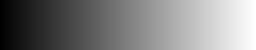

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (256, 50))
for x in range(256):
    for y in range(50):
        bild.putpixel((x, y), (x, x, x))
bild
```

</details>

#### Aufgabe 3.2

Erzeuge einen **senkrechten** Verlauf mit 200 × 200 Pixeln: oben Blau `(0, 0, 255)`, unten Gelb `(255, 255, 0)`. Der Rot- und Grünanteil ist `y * 255 // 199`, der Blauanteil
`255` minus diesen Wert.

**Erwartete Ausgabe:**



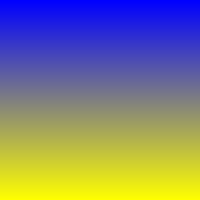

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (200, 200))
for y in range(200):
    wert = y * 255 // 199
    for x in range(200):
        bild.putpixel((x, y), (wert, wert, 255 - wert))
bild
```

</details>

#### Aufgabe 3.3

Erzeuge ein Schachbrett mit 8 × 8 Feldern zu je 25 × 25 Pixeln (200 × 200 Pixel). Ein Feld ist schwarz, wenn `(x // 25 + y // 25) % 2 == 0`, sonst weiß.

**Erwartete Ausgabe:**



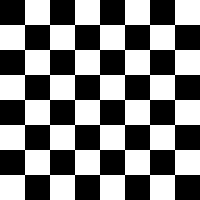

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (200, 200))
for x in range(200):
    for y in range(200):
        if (x // 25 + y // 25) % 2 == 0:
            bild.putpixel((x, y), (0, 0, 0))
        else:
            bild.putpixel((x, y), (255, 255, 255))
bild
```

</details>

#### Aufgabe 3.4

Erzeuge die Flagge von Deutschland mit 300 × 180 Pixeln: drei gleich hohe Streifen Schwarz, Rot `(221, 0, 0)` und Gold `(255, 206, 0)`.

**Erwartete Ausgabe:**



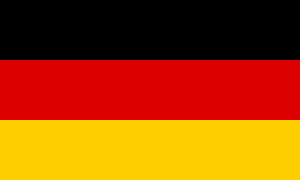

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (300, 180))
for y in range(180):
    if y < 60:
        farbe = (0, 0, 0)
    elif y < 120:
        farbe = (221, 0, 0)
    else:
        farbe = (255, 206, 0)
    for x in range(300):
        bild.putpixel((x, y), farbe)
bild
```

</details>

#### Aufgabe 3.5

Zeichne einen roten Kreis mit dem Radius 60 in die Mitte eines weißen 200 × 200-Bilds: Ein Pixel gehört zum Kreis, wenn `(x - 100)² + (y - 100)² <= 60²` ist.
Zähle die roten Pixel und vergleiche mit der Kreisfläche `π · 60²` (gerundet).

**Erwartete Ausgabe:**

```
11289 11310
```

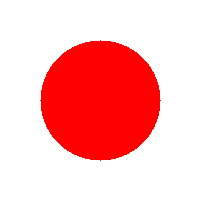

In [ ]:
from PIL import Image
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
import math
bild = Image.new('RGB', (200, 200), 'white')
anzahl = 0
for x in range(200):
    for y in range(200):
        if (x - 100) ** 2 + (y - 100) ** 2 <= 60 ** 2:
            bild.putpixel((x, y), (255, 0, 0))
            anzahl += 1
print(anzahl, round(math.pi * 60 ** 2))
bild
```

</details>

#### Aufgabe 3.6

Erzeuge ein Bild mit 255 × 255 Pixeln, in dem der Rotanteil `x` und der Grünanteil `y` ist (Blau 0). Oben links ist es schwarz, unten rechts gelb.

**Erwartete Ausgabe:**



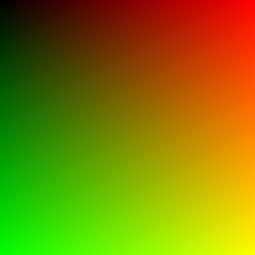

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (255, 255))
for x in range(255):
    for y in range(255):
        bild.putpixel((x, y), (x, y, 0))
bild
```

</details>

#### Aufgabe 3.7

Erzeuge ein Bild mit 200 × 200 Pixeln aus zufällig gefärbten Pixeln (`random.randint(0, 255)` für jeden Farbanteil, `random.seed(1)` vorher).
Es sieht aus wie das Rauschen eines alten Fernsehers.

**Erwartete Ausgabe:**



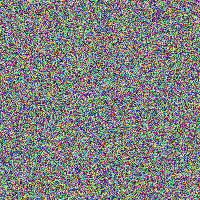

In [ ]:
from PIL import Image
import random
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
import random
random.seed(1)
bild = Image.new('RGB', (200, 200))
for x in range(200):
    for y in range(200):
        bild.putpixel((x, y), (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255)))
bild
```

</details>

#### Aufgabe 3.8

Schreibe eine Funktion `streifen(breite, hoehe, farben)`, die ein Bild mit senkrechten, gleich breiten Streifen in den Farben der Liste `farben` zurückgibt.
Erzeuge damit die Flagge von Frankreich (`'#002395'`, `'white'`, `'#ed2939'`, 300 × 200) und die von Italien (`'#009246'`, `'white'`, `'#ce2b37'`).
`putpixel()` braucht ein Tupel, deshalb rechnest du die Farben mit `ImageColor.getrgb()` um.

**Erwartete Ausgabe:**



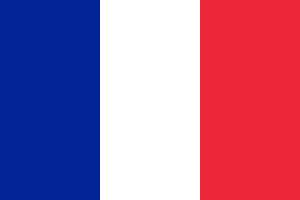

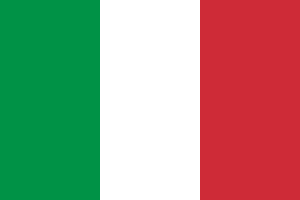

In [ ]:
from PIL import Image, ImageColor
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageColor

def streifen(breite, hoehe, farben):
    bild = Image.new('RGB', (breite, hoehe))
    for x in range(breite):
        farbe = ImageColor.getrgb(farben[x * len(farben) // breite])
        for y in range(hoehe):
            bild.putpixel((x, y), farbe)
    return bild

display(streifen(300, 200, ['#002395', 'white', '#ed2939']))
display(streifen(300, 200, ['#009246', 'white', '#ce2b37']))
```

</details>

#### Aufgabe 3.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image

bild = Image.new('RGB', (4, 1))
for x in range(4):
    bild.putpixel((x, 0), (x * 80, 0, 0))
print(bild.getpixel((3, 0)))
print(bild.getpixel((0, 0)))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
(240, 0, 0)
(0, 0, 0)
```

Der Rotanteil ist `x · 80`: für `x = 3` also 240, für `x = 0` gleich 0. Ausgabe: `(240, 0, 0)` und `(0, 0, 0)`.

</details>

## 4. Modi: Graustufen und Transparenz

#### `L`, `RGB` und `RGBA`

Der Modus bestimmt, was in einem Pixel steht:

| Modus | Pixel | Bedeutung |
|---|---|---|
| `'L'` | eine Zahl 0 bis 255 | Graustufen (*luminance*, Helligkeit) |
| `'RGB'` | Tupel mit 3 Zahlen | Farbe |
| `'RGBA'` | Tupel mit 4 Zahlen | Farbe und **Alpha** (Deckkraft: 0 durchsichtig, 255 deckend) |
| `'1'` | 0 oder 255 | nur Schwarz und Weiß |

`bild.convert('L')` wandelt in einen anderen Modus um, `bild.getbands()` gibt die Namen der **Kanäle** zurück. Graustufen berechnet Pillow mit
`L = 0.299·R + 0.587·G + 0.114·B`: Grün wirkt für das Auge heller als Rot und Blau.

In [ ]:
from PIL import Image

farbig = Image.new('RGB', (100, 50), (255, 0, 0))
grau = farbig.convert('L')
print(farbig.getbands(), grau.getbands())
print(grau.getpixel((0, 0)))
print(Image.new('RGB', (1, 1), (0, 255, 0)).convert('L').getpixel((0, 0)))
grau

#### Aufgabe 4.1

Wandle die Farben Rot, Grün, Blau, Gelb und Weiß jeweils in Graustufen um (1 × 1-Bilder) und gib die Helligkeit aus.

**Erwartete Ausgabe:**

```
(255, 0, 0) 76
(0, 255, 0) 150
(0, 0, 255) 29
(255, 255, 0) 226
(255, 255, 255) 255
```

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
for farbe in [(255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 255, 0), (255, 255, 255)]:
    print(farbe, Image.new('RGB', (1, 1), farbe).convert('L').getpixel((0, 0)))
```

</details>

#### Aufgabe 4.2

Erzeuge direkt ein Graustufenbild (`Image.new('L', (256, 50))`) mit einem Verlauf von Schwarz nach Weiß. Im Modus `L` ist jedes Pixel eine einzelne Zahl.

**Erwartete Ausgabe:**



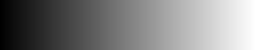

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('L', (256, 50))
for x in range(256):
    for y in range(50):
        bild.putpixel((x, y), x)
bild
```

</details>

#### Aufgabe 4.3

Öffne `bluete.png`, wandle es in Graustufen um und zeige beide Bilder an. Gib die Modi und die Farbe bzw. Helligkeit des Pixels `(320, 213)` aus.

**Erwartete Ausgabe:**

```
RGB L
(143, 1, 0) 43
```

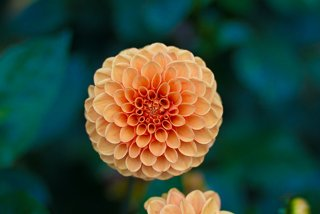

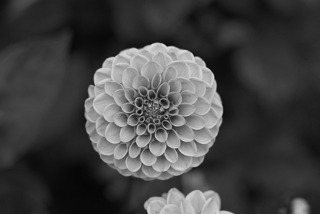

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
foto = Image.open('bluete.png')
grau = foto.convert('L')
print(foto.mode, grau.mode)
print(foto.getpixel((320, 213)), grau.getpixel((320, 213)))
display(foto)
display(grau)
```

</details>

#### Aufgabe 4.4

Wandle das Graustufen-Verlaufsbild in den Modus `'1'` (nur Schwarz und Weiß) um. Pillow verteilt dabei schwarze und weiße Punkte so, dass es von Weitem grau aussieht
(**Rastern**, *dithering*). Zeige das Ergebnis 2-fach vergrößert an.

**Erwartete Ausgabe:**

```
1 0 255
```

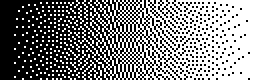

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('L', (128, 40))
for x in range(128):
    for y in range(40):
        bild.putpixel((x, y), x * 2)
sw = bild.convert('1')
print(sw.mode, sw.getpixel((0, 0)), sw.getpixel((127, 0)))
sw.resize((256, 80), Image.NEAREST)
```

</details>

#### Aufgabe 4.5

Ein RGBA-Bild mit halbdurchsichtigem Rot: Erzeuge `Image.new('RGBA', (100, 100), (255, 0, 0, 128))`, gib seine Kanäle und ein Pixel aus und zeige es an. Vor dem Hintergrund
der Ausgabe wirkt es rosa, weil der Hintergrund durchscheint.

**Erwartete Ausgabe:**

```
('R', 'G', 'B', 'A')
(255, 0, 0, 128)
```

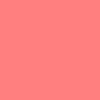

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGBA', (100, 100), (255, 0, 0, 128))
print(bild.getbands())
print(bild.getpixel((0, 0)))
bild
```

</details>

#### Aufgabe 4.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image

bild = Image.new('L', (3, 3), 100)
print(bild.getpixel((1, 1)))
print(bild.convert('RGB').getpixel((1, 1)))
print(len(bild.getbands()), len(bild.convert('RGBA').getbands()))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
100
(100, 100, 100)
1 4
```

- Im Modus `L` ist ein Pixel eine Zahl: `100`.
- Beim Umwandeln nach RGB bekommen alle drei Anteile denselben Wert: `(100, 100, 100)`.
- `L` hat einen Kanal, `RGBA` vier: `1 4`.

</details>

## 5. Speichern und öffnen

#### `save()` und `Image.open()`

- `bild.save('name.png')` speichert das Bild. Das Format ergibt sich aus der Dateiendung: `.png` (verlustfrei, gut für Grafiken), `.jpg` (verlustbehaftet, klein, gut für Fotos),
  `.gif`, `.bmp` u. a. Bei JPEG gibt `quality=...` (1 bis 95) die Qualität an.
- `Image.open('name.png')` öffnet eine Bilddatei. `bild.format` ist das Dateiformat.

In JupyterLite liegen die Dateien im Speicher des Browsers; in der Dateiliste links kannst du sie ansehen und herunterladen (Rechtsklick → *Download*).
JPEG kann keine Transparenz speichern; ein RGBA-Bild muss vorher mit `convert('RGB')` umgewandelt werden.

In [ ]:
from PIL import Image

bild = Image.new('RGB', (100, 60), 'teal')
bild.save('tuerkis.png')
bild.save('tuerkis.jpg', quality=90)
for name in ['tuerkis.png', 'tuerkis.jpg']:
    geladen = Image.open(name)
    print(name, geladen.format, geladen.size, geladen.mode)

#### Aufgabe 5.1

Erzeuge ein rotes 50 × 50-Bild, speichere es als `rot.png` und als `rot.bmp`, öffne beide wieder und gib Format und Größe aus.

**Erwartete Ausgabe:**

```
PNG (50, 50)
BMP (50, 50)
```

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (50, 50), 'red')
bild.save('rot.png')
bild.save('rot.bmp')
for name in ['rot.png', 'rot.bmp']:
    geladen = Image.open(name)
    print(geladen.format, geladen.size)
```

</details>

#### Aufgabe 5.2

PNG ist verlustfrei, JPEG nicht: Speichere den Farbverlauf aus Abschnitt 3 (256 × 100, `(x, 0, 255 - x)`) als PNG und als JPEG mit `quality=10`, öffne beide und gib die
Farbe des Pixels `(100, 50)` aus. Beim PNG ist sie genau `(100, 0, 155)`.

In [ ]:
from PIL import Image
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (256, 100))
for x in range(256):
    for y in range(100):
        bild.putpixel((x, y), (x, 0, 255 - x))
bild.save('verlauf.png')
bild.save('verlauf.jpg', quality=10)
print(Image.open('verlauf.png').getpixel((100, 50)))
print(Image.open('verlauf.jpg').getpixel((100, 50)))
```

</details>

#### Aufgabe 5.3

Öffne `pagode.png` und gib Format, Größe, Modus und die Anzahl der Pixel aus. Zeige das Foto an.

**Erwartete Ausgabe:**

```
PNG (640, 427) RGB
273280
```

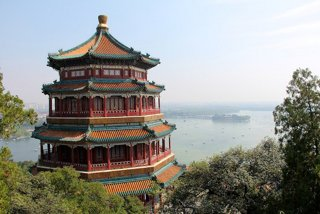

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
foto = Image.open('pagode.png')
print(foto.format, foto.size, foto.mode)
print(foto.width * foto.height)
foto
```

</details>

#### Aufgabe 5.4

Ein RGBA-Bild als JPEG speichern: Versuche es mit `Image.new('RGBA', (40, 40), (0, 0, 255, 100))` direkt (das gibt einen Fehler) und fange den Fehler mit `try`/`except OSError` ab.
Wandle das Bild danach in RGB um und speichere es als `blau.jpg`.

**Erwartete Ausgabe:**

```
JPEG kann keine Transparenz speichern.
RGB
```

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGBA', (40, 40), (0, 0, 255, 100))
try:
    bild.save('blau.jpg')
except OSError:
    print('JPEG kann keine Transparenz speichern.')
bild.convert('RGB').save('blau.jpg')
print(Image.open('blau.jpg').mode)
```

</details>

#### Aufgabe 5.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image

Image.new('L', (30, 20), 0).save('schwarz.png')
bild = Image.open('schwarz.png')
print(bild.format, bild.mode, bild.size)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
PNG L (30, 20)
```

Das Bild wird als PNG gespeichert und wieder geöffnet. Format, Modus und Größe bleiben erhalten: `PNG L (30, 20)`.

</details>

## 6. Gemischte Übungen

#### Aufgabe 6.1

Erzeuge die Flagge von Japan: weißes Bild 300 × 200 mit einem roten Kreis (`'#bc002d'`) in der Mitte, Radius 60.

**Erwartete Ausgabe:**



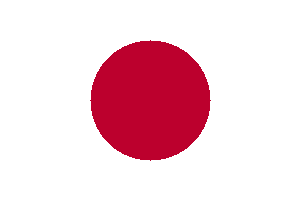

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (300, 200), 'white')
for x in range(300):
    for y in range(200):
        if (x - 150) ** 2 + (y - 100) ** 2 <= 60 ** 2:
            bild.putpixel((x, y), (188, 0, 45))
bild
```

</details>

#### Aufgabe 6.2

Erzeuge ein Bild mit 200 × 200 Pixeln mit **Ringen**: Die Farbe hängt vom Abstand `d` des Pixels zur Mitte ab; ist `int(d) // 10` gerade, ist das Pixel blau, sonst weiß.
Den Abstand berechnest du mit `math.sqrt()` oder `math.dist()`.

**Erwartete Ausgabe:**



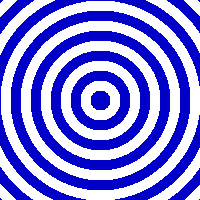

In [ ]:
from PIL import Image
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
import math
bild = Image.new('RGB', (200, 200))
for x in range(200):
    for y in range(200):
        d = math.dist((x, y), (100, 100))
        if int(d) // 10 % 2 == 0:
            bild.putpixel((x, y), (0, 0, 200))
        else:
            bild.putpixel((x, y), (255, 255, 255))
bild
```

</details>

#### Aufgabe 6.3

Erzeuge ein Bild mit 256 × 256 Pixeln, in dem jedes Pixel die Farbe `(x * y % 256, x, 255 - y)` hat. Durch den Modulo-Operator entsteht ein
überraschendes Muster aus Bögen.

**Erwartete Ausgabe:**



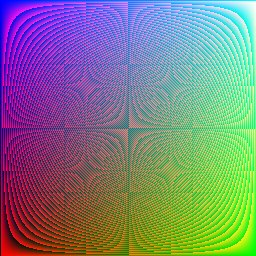

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
bild = Image.new('RGB', (256, 256))
for x in range(256):
    for y in range(256):
        bild.putpixel((x, y), (x * y % 256, x, 255 - y))
bild
```

</details>

#### Aufgabe 6.4

Zähle im Foto `bluete.png` die Pixel, deren Rotanteil größer ist als Grün- und Blauanteil zusammen („sehr rote“ Pixel), und gib die Anzahl und ihren Anteil an
allen Pixeln aus (3 Nachkommastellen). Das dauert ein paar Sekunden.

**Erwartete Ausgabe:**

```
25999
0.095
```

In [ ]:
from PIL import Image
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image
foto = Image.open('bluete.png')
anzahl = 0
for x in range(foto.width):
    for y in range(foto.height):
        r, g, b = foto.getpixel((x, y))
        if r > g + b:
            anzahl += 1
print(anzahl)
print(f'{anzahl / (foto.width * foto.height):.3f}')
```

</details>

#### Aufgabe 6.5

Gestalte ein eigenes Bild mit Schleifen und Bedingungen (z. B. eine andere Flagge, ein Muster, ein Pixel-Kunstwerk) und speichere es als PNG.

In [ ]:
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image

bild = Image.new('RGB', (300, 200), 'white')
for x in range(300):
    for y in range(200):
        if abs(x - 150) + abs(y - 100) < 80:
            bild.putpixel((x, y), (x % 256, y, 150))
bild.save('raute.png')
bild
```

</details>